In [1]:
import spacy
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from spacy import displacy
import json

# Load pretrained English model
nlp = spacy.load("en_core_web_sm")

print("spaCy model loaded successfully!")

spaCy model loaded successfully!


### Task 1: Coarse vs Fine-Grained POS Tags
` Given sentence: `

"The quick brown fox jumped over the lazy dogs near the river."

a, b) Print tokens with coarse and fine-grained tags

In [2]:
text = "The quick brown fox jumped over the lazy dogs near the river."

doc = nlp(text)

print(f"{'Token':<15} {'POS':<15} {'TAG':<15}")
print("-" * 45)

for token in doc:
    print(f"{token.text:<15} {token.pos_:<15} {token.tag_:<15}")

Token           POS             TAG            
---------------------------------------------
The             DET             DT             
quick           ADJ             JJ             
brown           ADJ             JJ             
fox             NOUN            NN             
jumped          VERB            VBD            
over            ADP             IN             
the             DET             DT             
lazy            ADJ             JJ             
dogs            NOUN            NNS            
near            ADP             IN             
the             DET             DT             
river           NOUN            NN             
.               PUNCT           .              


c) Explain every unique POS and TAG

In [3]:
pos_tags = set()
fine_tags = set()

for token in doc:
    pos_tags.add(token.pos_)
    fine_tags.add(token.tag_)

print("COARSE POS TAG EXPLANATIONS")

for tag in sorted(pos_tags):
    print(tag, ":", spacy.explain(tag))

print("\nFINE-GRAINED TAG EXPLANATIONS")

for tag in sorted(fine_tags):
    print(tag, ":", spacy.explain(tag))

COARSE POS TAG EXPLANATIONS
ADJ : adjective
ADP : adposition
DET : determiner
NOUN : noun
PUNCT : punctuation
VERB : verb

FINE-GRAINED TAG EXPLANATIONS
. : punctuation mark, sentence closer
DT : determiner
IN : conjunction, subordinating or preposition
JJ : adjective (English), other noun-modifier (Chinese)
NN : noun, singular or mass
NNS : noun, plural
VBD : verb, past tense


d) Find POS tags having multiple fine-grained tags

We will create a dictionary where each coarse POS tag stores its unique fine-grained tags

In [4]:
pos_to_fine = defaultdict(set)

for token in doc:
    pos_to_fine[token.pos_].add(token.tag_)

print("Distinct fine-grained tags for each POS:\n")

for pos, tags in sorted(pos_to_fine.items()):

    print(pos, ":", sorted(tags))

    print("Number of distinct TAG values:", len(tags))

    if len(tags) > 1:
        print("This POS has multiple fine-grained tags.")

    print()

Distinct fine-grained tags for each POS:

ADJ : ['JJ']
Number of distinct TAG values: 1

ADP : ['IN']
Number of distinct TAG values: 1

DET : ['DT']
Number of distinct TAG values: 1

NOUN : ['NN', 'NNS']
Number of distinct TAG values: 2
This POS has multiple fine-grained tags.

PUNCT : ['.']
Number of distinct TAG values: 1

VERB : ['VBD']
Number of distinct TAG values: 1



### Task 2: Tag Frequency Analysis
` Given paragraph: `

"Ali bought three fresh apples. He carefully washed them and quickly shared them with his friends. Everyone happily enjoyed the sweet fruit."

a, b) Count POS and TAG frequencies

In [5]:
text = """
Ali bought three fresh apples.
He carefully washed them and quickly shared them with his
friends. Everyone happily enjoyed the sweet fruit.
"""

doc = nlp(text)

pos_counts = Counter()
tag_counts = Counter()

for token in doc:

    pos_counts[token.pos_] += 1

    tag_counts[token.tag_] += 1


print("POS TAG FREQUENCIES")

for tag, count in pos_counts.most_common():
    print(tag, ":", count)


print("\nFINE-GRAINED TAG FREQUENCIES")

for tag, count in tag_counts.most_common():
    print(tag, ":", count)

POS TAG FREQUENCIES
PRON : 5
SPACE : 4
VERB : 4
NOUN : 3
PUNCT : 3
ADV : 3
ADJ : 2
PROPN : 1
NUM : 1
CCONJ : 1
ADP : 1
DET : 1

FINE-GRAINED TAG FREQUENCIES
_SP : 4
VBD : 4
. : 3
PRP : 3
RB : 3
JJ : 2
NNS : 2
NN : 2
NNP : 1
CD : 1
CC : 1
IN : 1
PRP$ : 1
DT : 1


c) Dictionaries sorted by frequency

In [6]:
sorted_pos = dict(
    sorted(pos_counts.items(), key=lambda item: item[1], reverse=True)
)

sorted_tag = dict(
    sorted(tag_counts.items(), key=lambda item: item[1], reverse=True)
)

print("Sorted POS Dictionary:")
print(sorted_pos)

print("\nSorted TAG Dictionary:")
print(sorted_tag)

Sorted POS Dictionary:
{'PRON': 5, 'SPACE': 4, 'VERB': 4, 'NOUN': 3, 'PUNCT': 3, 'ADV': 3, 'ADJ': 2, 'PROPN': 1, 'NUM': 1, 'CCONJ': 1, 'ADP': 1, 'DET': 1}

Sorted TAG Dictionary:
{'_SP': 4, 'VBD': 4, '.': 3, 'PRP': 3, 'RB': 3, 'JJ': 2, 'NNS': 2, 'NN': 2, 'NNP': 1, 'CD': 1, 'CC': 1, 'IN': 1, 'PRP$': 1, 'DT': 1}


d) Plot POS frequency bar chart

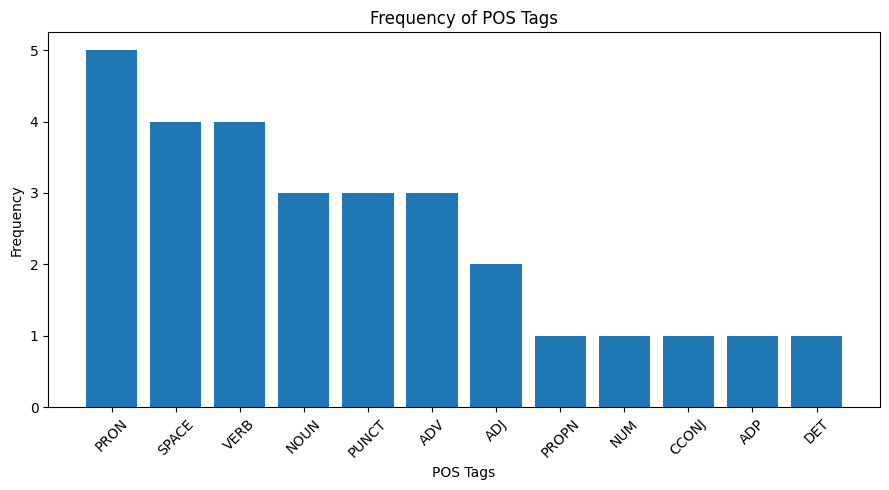

In [7]:
plt.figure(figsize=(9, 5))

plt.bar(
    sorted_pos.keys(),
    sorted_pos.values()
)

plt.xlabel("POS Tags")
plt.ylabel("Frequency")
plt.title("Frequency of POS Tags")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### Task 3: Context-Dependent Tagging
`Given sentences:`

In [8]:
sentences = [
    "I will book a flight to Lahore.",
    "She read a good book yesterday.",
    "They run every morning.",
    "We watched the run of the play."
]

a) Print the word "book" with POS and TAG

In [9]:
for sentence in sentences:

    doc = nlp(sentence)

    for token in doc:

        if token.text.lower() == "book":

            print("Sentence:", sentence)
            print("Word:", token.text)
            print("POS:", token.pos_)
            print("TAG:", token.tag_)
            print()

Sentence: I will book a flight to Lahore.
Word: book
POS: VERB
TAG: VB

Sentence: She read a good book yesterday.
Word: book
POS: NOUN
TAG: NN



b) Print the word "run" with POS and TAG

In [10]:
for sentence in sentences:

    doc = nlp(sentence)

    for token in doc:

        if token.text.lower() == "run":

            print("Sentence:", sentence)
            print("Word:", token.text)
            print("POS:", token.pos_)
            print("TAG:", token.tag_)
            print()

Sentence: They run every morning.
Word: run
POS: VERB
TAG: VBP

Sentence: We watched the run of the play.
Word: run
POS: NOUN
TAG: NN



c) Create compare_word() function

The function takes a word and a list of sentences and returns:

`(sentence_index, pos_, tag_)`

In [11]:
def compare_word(word, sentences):

    results = []

    for index, sentence in enumerate(sentences):

        doc = nlp(sentence)

        for token in doc:

            if token.text.lower() == word.lower():

                results.append(
                    (index + 1, token.pos_, token.tag_)
                )

    return results


print("BOOK:")
print(compare_word("book", sentences))

print("\nRUN:")
print(compare_word("run", sentences))

BOOK:
[(1, 'VERB', 'VB'), (2, 'NOUN', 'NN')]

RUN:
[(3, 'VERB', 'VBP'), (4, 'NOUN', 'NN')]


d) Test with two additional ambiguous words

We will use light and watch.

In [12]:
light_sentences = [
    "The light is very bright.",
    "Please light the candle."
]

watch_sentences = [
    "I bought a new watch.",
    "They watch television every evening."
]


print("LIGHT:")
print(compare_word("light", light_sentences))

print("\nWATCH:")
print(compare_word("watch", watch_sentences))

LIGHT:
[(1, 'NOUN', 'NN'), (2, 'VERB', 'VB')]

WATCH:
[(1, 'NOUN', 'NN'), (2, 'VERB', 'VBP')]


### Task 4: Filtering Noise Tokens
`Given messy text:`

In [13]:
text = " Hello!!! The price is $45.50 ... (really?)\n\n Is it worth it? xyz123 @@ "

a) Print all tokens, including noise tokens

In [14]:
doc = nlp(text)

print(f"{'TOKEN':<15} {'POS':<15}")
print("-" * 30)

for token in doc:

    print(f"{token.text:<15} {token.pos_:<15}")

TOKEN           POS            
------------------------------
                SPACE          
Hello           INTJ           
!               PUNCT          
!               PUNCT          
!               PUNCT          
The             DET            
price           NOUN           
is              AUX            
$               SYM            
45.50           NUM            
...             PUNCT          
(               PUNCT          
really          ADV            
?               PUNCT          
)               PUNCT          


              SPACE          
Is              AUX            
it              PRON           
worth           ADJ            
it              PRON           
?               PUNCT          
xyz123          PROPN          
@@              PROPN          


b) Remove SPACE, PUNCT and X tokens

In [15]:
cleaned_tokens = [
    token for token in doc
    if token.pos_ not in ["SPACE", "PUNCT", "X"]
]

print("Cleaned Tokens:")

print([token.text for token in cleaned_tokens])

Cleaned Tokens:
['Hello', 'The', 'price', 'is', '$', '45.50', 'really', 'Is', 'it', 'worth', 'it', 'xyz123', '@@']


c) Count removed tokens and percentage

In [16]:
original_count = len(doc)

cleaned_count = len(cleaned_tokens)

removed_count = original_count - cleaned_count

if original_count > 0:
    percentage = (removed_count / original_count) * 100
else:
    percentage = 0

print("Original tokens:", original_count)

print("Cleaned tokens:", cleaned_count)

print("Removed tokens:", removed_count)

print("Percentage removed:", round(percentage, 2), "%")

Original tokens: 23
Cleaned tokens: 13
Removed tokens: 10
Percentage removed: 43.48 %


d) Create reusable clean_pos() function

In [17]:
def clean_pos(text, remove=("SPACE", "PUNCT", "X")):

    doc = nlp(text)

    cleaned = [
        (token.text, token.pos_)
        for token in doc
        if token.pos_ not in remove
    ]

    return cleaned


# Test with another text containing noise tokens

test_text = "Wow!!! Python is great @@@ and useful... 123abc"

result = clean_pos(test_text)

print("Cleaned result:")

print(result)

Cleaned result:
[('Wow', 'INTJ'), ('Python', 'NOUN'), ('is', 'AUX'), ('great', 'ADJ'), ('@@@', 'PROPN'), ('and', 'CCONJ'), ('useful', 'ADJ'), ('123abc', 'NUM')]


### Task 5: Extracting Specific Parts of Speech
`Given text:`

"Fatima quickly opened the old wooden door and slowly walked into the dark room. She carefully placed a small lamp on the heavy table."

a) Extract all nouns and proper nouns

In [18]:
text = """
Fatima quickly opened the old wooden door and slowly walked
into the dark room. She carefully placed a small lamp on
the heavy table.
"""

doc = nlp(text)

nouns = [
    token.text
    for token in doc
    if token.pos_ in ["NOUN", "PROPN"]
]

print("Nouns and Proper Nouns:")

print(nouns)

Nouns and Proper Nouns:
['Fatima', 'door', 'room', 'lamp', 'table']


b) Extract verbs with their lemmas
A lemma is the base or dictionary form of a word.

For example:
- opened → open
- walked → walk
- placed → place

In [19]:
verbs = [
    (token.text, token.lemma_)
    for token in doc
    if token.pos_ == "VERB"
]

print("Verbs and their Lemmas:")

for word, lemma in verbs:

    print(word, "->", lemma)

Verbs and their Lemmas:
opened -> open
walked -> walk
placed -> place


c) Extract adjective-noun pairs

We use token indices to check whether an adjective is directly before a noun.

In [ ]:
pairs = []

for token in doc:

    if token.pos_ == "ADJ":

        next_index = token.i + 1

        if next_index < len(doc):

            next_token = doc[next_index]

            if next_token.pos_ in ["NOUN", "PROPN"]:

                pair = token.text + " " + next_token.text

                pairs.append(pair)


print("Adjective-Noun Pairs:")

print(pairs)

Adjective-Noun Pairs:
['wooden door', 'dark room', 'small lamp', 'heavy table']


d) Print summary table

In [21]:
noun_count = sum(
    1 for token in doc
    if token.pos_ in ["NOUN", "PROPN"]
)

verb_count = sum(
    1 for token in doc
    if token.pos_ == "VERB"
)

adjective_count = sum(
    1 for token in doc
    if token.pos_ == "ADJ"
)

adverb_count = sum(
    1 for token in doc
    if token.pos_ == "ADV"
)


print("\nPOS SUMMARY")
print("-" * 35)

print(f"{'Category':<20} {'Count':<10}")
print("-" * 35)

print(f"{'Nouns':<20} {noun_count:<10}")
print(f"{'Verbs':<20} {verb_count:<10}")
print(f"{'Adjectives':<20} {adjective_count:<10}")
print(f"{'Adverbs':<20} {adverb_count:<10}")

print("-" * 35)


POS SUMMARY
-----------------------------------
Category             Count     
-----------------------------------
Nouns                5         
Verbs                3         
Adjectives           5         
Adverbs              3         
-----------------------------------


### Task 6: Basic Named Entity Recognition (NER)
`Given text:`

"Imran Khan visited Google headquarters in California on March 3, 2019, and discussed a $2 million investment for Pakistan. Later, Microsoft and Amazon announced new offices in Lahore."

a) Extract entities with labels and character positions

In [ ]:
text = """
Imran Khan visited Google headquarters in California on March 3, 2019,
and discussed a $2 million investment for Pakistan.
Later, Microsoft and Amazon announced new offices in Lahore.
"""

doc = nlp(text)

print("NAMED ENTITIES")
print("-" * 60)

for ent in doc.ents:

    print("Entity:", ent.text)
    print("Label:", ent.label_)
    print("Start position:", ent.start_char)
    print("End position:", ent.end_char)
    print() 

NAMED ENTITIES
------------------------------------------------------------
Entity: Imran Khan
Label: PERSON
Start position: 1
End position: 11

Entity: Google
Label: ORG
Start position: 20
End position: 26

Entity: California
Label: GPE
Start position: 43
End position: 53

Entity: March 3, 2019
Label: DATE
Start position: 57
End position: 70

Entity: $2 million
Label: MONEY
Start position: 88
End position: 98

Entity: Pakistan
Label: GPE
Start position: 114
End position: 122

Entity: Microsoft
Label: ORG
Start position: 131
End position: 140

Entity: Amazon
Label: ORG
Start position: 145
End position: 151

Entity: Lahore
Label: GPE
Start position: 177
End position: 183



b) Explain every unique entity label

In [23]:
labels = set()

for ent in doc.ents:
    labels.add(ent.label_)


print("ENTITY LABEL EXPLANATIONS")

for label in sorted(labels):

    print(label, ":", spacy.explain(label))

ENTITY LABEL EXPLANATIONS
DATE : Absolute or relative dates or periods
GPE : Countries, cities, states
MONEY : Monetary values, including unit
ORG : Companies, agencies, institutions, etc.
PERSON : People, including fictional


c) Group entities by label in a dictionary

In [24]:
entities_by_label = defaultdict(list)

for ent in doc.ents:

    entities_by_label[ent.label_].append(ent.text)


entities_by_label = dict(entities_by_label)

print("Entities Grouped by Label:")

print(entities_by_label)

Entities Grouped by Label:
{'PERSON': ['Imran Khan'], 'ORG': ['Google', 'Microsoft', 'Amazon'], 'GPE': ['California', 'Pakistan', 'Lahore'], 'DATE': ['March 3, 2019'], 'MONEY': ['$2 million']}


d) Count entities of each type and find the highest count

In [25]:
entity_counts = Counter(
    ent.label_ for ent in doc.ents
)

print("ENTITY COUNTS")

for label, count in entity_counts.most_common():

    print(label, ":", count)


if entity_counts:

    highest_label = entity_counts.most_common(1)[0]

    print("\nLabel with highest count:")

    print(highest_label[0], "with", highest_label[1], "entities")

else:

    print("No entities found.")

ENTITY COUNTS
ORG : 3
GPE : 3
PERSON : 1
DATE : 1
MONEY : 1

Label with highest count:
ORG with 3 entities


### Task 7: Visualizing Entities with displaCy
`Given text:`

"Apple opened a new store in Karachi in June 2023. Tim Cook said the company plans to invest 500 million dollars across Asia by 2025."

a) Render entities and save as entities.html

In [47]:
text = """
Apple opened a new store in Karachi in June 2023.
Tim Cook said the company plans to invest
500 million dollars across Asia by 2025.
"""

doc = nlp(text)

# Render entity visualization as HTML
html = displacy.render(
    doc,
    style="ent",
    page=True,
    jupyter=False
)

# Save HTML file
with open("entities.html", "w", encoding="utf-8") as file:

    file.write(html)


print("Entity visualization saved as entities.html")

Entity visualization saved as entities.html


b) Highlight only ORG and GPE entities

ORG represents organizations, while GPE represents geopolitical entities such as countries, cities, and states.

In [46]:
options = {
    "ents": ["ORG", "GPE"]
}

html = displacy.render(
    doc,
    style="ent",
    options=options,
    page=True,
    jupyter=False
)

with open("entities_filtered.html", "w", encoding="utf-8") as file:

    file.write(html)


print("Filtered entity visualization saved.")

Filtered entity visualization saved.


c) Customize entity colors

In [45]:
colors = {
    "ORG": "#FFA500",
    "GPE": "#90EE90"
}

options = {
    "ents": ["ORG", "GPE"],
    "colors": colors
}

html = displacy.render(
    doc,
    style="ent",
    options=options,
    page=True,
    jupyter=False
)

with open("entities_colored.html", "w", encoding="utf-8") as file:

    file.write(html)


print("Colored entity visualization saved.")

Colored entity visualization saved.


d) Render dependency visualization for the first sentence

Dependency visualization displays grammatical relationships between words.

In [44]:
# Get the first sentence
first_sentence = list(doc.sents)[0]

# Render dependency visualization
html = displacy.render(
    first_sentence,
    style="dep",
    page=True,
    jupyter=False
)

# Save HTML file
with open("dependency.html", "w", encoding="utf-8") as file:

    file.write(html)


print("Dependency visualization saved as dependency.html")

Dependency visualization saved as dependency.html


### Task 8: Extending the Model with EntityRuler
`Given text:`

"Dr. Zainab works at LabTech Solutions and uses the Python library NumPy and the framework TensorFlow. Her colleague Abbas prefers PyTorch and Pandas."

a) Process with the plain pretrained model

In [32]:
text = """
Dr. Zainab works at LabTech Solutions and uses the Python library
NumPy and the framework TensorFlow. Her colleague Abbas prefers
PyTorch and Pandas.
"""

doc = nlp(text)

print("ORIGINAL MODEL ENTITIES")

for ent in doc.ents:

    print(ent.text, "->", ent.label_)


tech_terms = ["NumPy", "TensorFlow", "PyTorch", "Pandas"]

detected_terms = [
    ent.text for ent in doc.ents
]

print("\nTECH TERM CHECK")

for term in tech_terms:

    matching_entities = [
        ent for ent in doc.ents
        if term.lower() in ent.text.lower()
    ]

    if matching_entities:

        print(term, "->", [
            ent.label_ for ent in matching_entities
        ])

    else:

        print(term, "-> Missed by the model")
        

ORIGINAL MODEL ENTITIES
Zainab -> PERSON
LabTech Solutions -> ORG
Abbas -> PERSON
PyTorch -> PERSON
Pandas -> PERSON

TECH TERM CHECK
NumPy -> Missed by the model
TensorFlow -> Missed by the model
PyTorch -> ['PERSON']
Pandas -> ['PERSON']


The pretrained model may not recognize these technology names as entities, or may assign them labels other than TECH. This is why we extend it with an EntityRuler.

b) Create EntityRuler and add TECH patterns

An EntityRuler allows us to define our own named entity patterns.

In [33]:
# Create a separate pipeline
nlp_ruler = spacy.load("en_core_web_sm")

# Add EntityRuler before NER
ruler = nlp_ruler.add_pipe(
    "entity_ruler",
    before="ner"
)

patterns = [
    {"label": "TECH", "pattern": "NumPy"},
    {"label": "TECH", "pattern": "TensorFlow"},
    {"label": "TECH", "pattern": "PyTorch"},
    {"label": "TECH", "pattern": "Pandas"}
]

ruler.add_patterns(patterns)

print("EntityRuler patterns added successfully.")

EntityRuler patterns added successfully.


c) Reprocess text and print new entities

In [34]:
doc = nlp_ruler(text)

print("UPDATED ENTITY LIST")

for ent in doc.ents:

    print(ent.text, "->", ent.label_)

UPDATED ENTITY LIST
Zainab -> PERSON
LabTech Solutions -> ORG
NumPy -> TECH
TensorFlow -> TECH
Abbas -> PERSON
PyTorch -> TECH
Pandas -> TECH


d) Experiment with overwrite_ents and ruler position

The overwrite_ents setting determines whether the ruler can replace an entity already recognized by the NER model.
- False: Existing entities are preserved when they overlap with a ruler match.
- True: Ruler matches can replace overlapping existing entities.
- before="ner": The ruler runs before the pretrained NER component.
- after="ner": The ruler runs after the pretrained NER component.
Experiment 1: EntityRuler before NER

In [35]:
nlp_before = spacy.load("en_core_web_sm")

ruler_before = nlp_before.add_pipe(
    "entity_ruler",
    before="ner",
    config={"overwrite_ents": False}
)

ruler_before.add_patterns(patterns)

doc_before = nlp_before(text)

print("RULER BEFORE NER")

for ent in doc_before.ents:

    print(ent.text, "->", ent.label_)

RULER BEFORE NER
Zainab -> PERSON
LabTech Solutions -> ORG
NumPy -> TECH
TensorFlow -> TECH
Abbas -> PERSON
PyTorch -> TECH
Pandas -> TECH


Experiment 2: EntityRuler after NER, overwrite disabled

In [36]:
nlp_after_false = spacy.load("en_core_web_sm")

ruler_after_false = nlp_after_false.add_pipe(
    "entity_ruler",
    after="ner",
    config={"overwrite_ents": False}
)

ruler_after_false.add_patterns(patterns)

doc_after_false = nlp_after_false(text)

print("RULER AFTER NER - OVERWRITE FALSE")

for ent in doc_after_false.ents:

    print(ent.text, "->", ent.label_)

RULER AFTER NER - OVERWRITE FALSE
Zainab -> PERSON
LabTech Solutions -> ORG
NumPy -> TECH
TensorFlow -> TECH
Abbas -> PERSON
PyTorch -> PERSON
Pandas -> PERSON


Experiment 3: EntityRuler after NER, overwrite enabled

In [37]:
nlp_after_true = spacy.load("en_core_web_sm")

ruler_after_true = nlp_after_true.add_pipe(
    "entity_ruler",
    after="ner",
    config={"overwrite_ents": True}
)

ruler_after_true.add_patterns(patterns)

doc_after_true = nlp_after_true(text)

print("RULER AFTER NER - OVERWRITE TRUE")

for ent in doc_after_true.ents:

    print(ent.text, "->", ent.label_)

RULER AFTER NER - OVERWRITE TRUE
Zainab -> PERSON
LabTech Solutions -> ORG
NumPy -> TECH
TensorFlow -> TECH
Abbas -> PERSON
PyTorch -> TECH
Pandas -> TECH


`What to observe:` Compare the three outputs. With overwrite enabled, the ruler can replace overlapping pretrained entities. The position of the ruler also affects which component processes the text first.

### Task 9: Complete Pipeline — From Raw Text to Structured Information
`Given text:`

"Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month. Investors in London and Tokyo reacted quickly, and Tesla shares rose by 4%."

a) Create a function to clean text and return tokens with POS and TAG

In [38]:
text = """
Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX
will launch a Falcon rocket from Texas next month.
Investors in London and Tokyo reacted quickly, and Tesla shares
rose by 4%.
"""


def clean_text(text):

    doc = nlp(text)

    cleaned_tokens = [
        {
            "token": token.text,
            "pos": token.pos_,
            "tag": token.tag_
        }
        for token in doc
        if token.pos_ not in ["SPACE", "PUNCT", "X"]
    ]

    return cleaned_tokens


tokens = clean_text(text)

print("CLEANED TOKENS")

for token in tokens:

    print(token)

CLEANED TOKENS
{'token': 'Elon', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'Musk', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'the', 'pos': 'DET', 'tag': 'DT'}
{'token': 'CEO', 'pos': 'NOUN', 'tag': 'NN'}
{'token': 'of', 'pos': 'ADP', 'tag': 'IN'}
{'token': 'Tesla', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'announced', 'pos': 'VERB', 'tag': 'VBN'}
{'token': 'on', 'pos': 'ADP', 'tag': 'IN'}
{'token': 'Tuesday', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'that', 'pos': 'SCONJ', 'tag': 'IN'}
{'token': 'SpaceX', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'will', 'pos': 'AUX', 'tag': 'MD'}
{'token': 'launch', 'pos': 'VERB', 'tag': 'VB'}
{'token': 'a', 'pos': 'DET', 'tag': 'DT'}
{'token': 'Falcon', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'rocket', 'pos': 'NOUN', 'tag': 'NN'}
{'token': 'from', 'pos': 'ADP', 'tag': 'IN'}
{'token': 'Texas', 'pos': 'PROPN', 'tag': 'NNP'}
{'token': 'next', 'pos': 'ADJ', 'tag': 'JJ'}
{'token': 'month', 'pos': 'NOUN', 'tag': 'NN'}
{'token': 'Investors', 'pos': 'NOUN', 'tag': '

b) Add EntityRuler with PRODUCT patterns

We want the terms Falcon and Tesla shares to be identified as PRODUCT.

In [39]:
# Create a new pipeline
nlp_final = spacy.load("en_core_web_sm")

# Add EntityRuler after NER
ruler = nlp_final.add_pipe(
    "entity_ruler",
    after="ner",
    config={"overwrite_ents": True}
)

# Define custom patterns
patterns = [
    {
        "label": "PRODUCT",
        "pattern": "Falcon"
    },
    {
        "label": "PRODUCT",
        "pattern": [
            {"LOWER": "tesla"},
            {"LOWER": "shares"}
        ]
    }
]

ruler.add_patterns(patterns)

# Process the text
doc = nlp_final(text)

print("FINAL ENTITIES")

for ent in doc.ents:

    print(ent.text, "->", ent.label_)

FINAL ENTITIES
Elon Musk -> PERSON
Tesla -> ORG
Tuesday -> DATE
Falcon -> PRODUCT
Texas -> GPE
next month -> DATE
London -> GPE
Tokyo -> GPE
Tesla shares -> PRODUCT
4% -> PERCENT


c) Create structured output and save as output.json
We need a dictionary with three keys:
- tokens
- entities
- pos_counts

In [40]:
# Extract cleaned tokens
cleaned_tokens = [
    {
        "token": token.text,
        "pos": token.pos_,
        "tag": token.tag_
    }
    for token in doc
    if token.pos_ not in ["SPACE", "PUNCT", "X"]
]


# Extract named entities
entities = [
    {
        "text": ent.text,
        "label": ent.label_,
        "start": ent.start_char,
        "end": ent.end_char
    }
    for ent in doc.ents
]


# Count POS tags
pos_counts = Counter(
    token.pos_
    for token in doc
    if token.pos_ not in ["SPACE", "PUNCT", "X"]
)


# Create structured dictionary
output = {

    "tokens": cleaned_tokens,

    "entities": entities,

    "pos_counts": dict(pos_counts)
}


# Save dictionary as JSON
with open("output.json", "w", encoding="utf-8") as file:

    json.dump(output, file, indent=4)


print("Structured output saved as output.json")

Structured output saved as output.json


d) Visualize final entities and print entity with its sentence

Customize colors for PERSON, ORG, GPE, and PRODUCT.

In [43]:
colors = {
    "PERSON": "#FF9999",
    "ORG": "#99CCFF",
    "GPE": "#99FF99",
    "PRODUCT": "#FFD700"
}

options = {
    "ents": ["PERSON", "ORG", "GPE", "PRODUCT"],
    "colors": colors
}


# Render final entity visualization
html = displacy.render(
    doc,
    style="ent",
    options=options,
    page=True,
    jupyter=False
)


# Save HTML file
with open("final_entities.html", "w", encoding="utf-8") as file:

    file.write(html)


print("Final entity visualization saved as final_entities.html")

Final entity visualization saved as final_entities.html


Print each entity together with its sentence:

In [42]:
print("ENTITY AND SENTENCE")

for ent in doc.ents:

    print("Entity:", ent.text)

    print("Label:", ent.label_)

    print("Sentence:", ent.sent.text)

    print("-" * 60)

ENTITY AND SENTENCE
Entity: Elon Musk
Label: PERSON
Sentence: 
Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX
will launch a Falcon rocket from Texas next month.

------------------------------------------------------------
Entity: Tesla
Label: ORG
Sentence: 
Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX
will launch a Falcon rocket from Texas next month.

------------------------------------------------------------
Entity: Tuesday
Label: DATE
Sentence: 
Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX
will launch a Falcon rocket from Texas next month.

------------------------------------------------------------
Entity: Falcon
Label: PRODUCT
Sentence: 
Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX
will launch a Falcon rocket from Texas next month.

------------------------------------------------------------
Entity: Texas
Label: GPE
Sentence: 
Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX
will launch a Falcon ro